# Reproduce: large language models for gene prioritisation from fetal ultrasound findings

Run All rebuilds every reported number from the committed inputs and model outputs, redraws the figures and compares
each regenerated file with the committed copy in `outputs/` and `work/`. It prints `REPRODUCED` when all agree.

* Hand-entered data: `inputs_manual/` (both extractions, adjudication log, final case table) and `inputs/pd_hpo/`
  (HPO coding of the pre-cutoff cohorts).
* Model answers are stored in `outputs/*.jsonl` and Exomiser results in `outputs/exomiser_2512*.json`,
  `v1/results/` and `v1p/results/`. Querying the models again is described at the end and is not part of Run All.
* Needs Python 3.12 (`requirements.txt`) and R with lme4. About 5 minutes on a laptop.

In [1]:
import json, os, shutil, subprocess, sys, tempfile
import pandas as pd
from IPython.display import Image, display
PY = sys.executable
def run(*args, out=None):
    r = subprocess.run(list(args), capture_output=True, text=True)
    if out:
        open(out, 'w').write(r.stdout + r.stderr)
    if r.returncode:
        print(r.stdout[-2000:], r.stderr[-2000:]); raise RuntimeError(' '.join(args))
    return r.stdout
subprocess.run(['bash', 'scripts/download.sh'], check=True)
# keep the committed results as the reference before anything is rebuilt
REF = tempfile.mkdtemp()
for d in ['outputs', 'work']:
    shutil.copytree(d, os.path.join(REF, d))
print('reference copy in', REF)

reference copy in /var/folders/8g/8_hhn6yd1x50b3h3y4n91mkh0000gn/T/tmpshfkk0vg


## 1. Case set
One record per fetus with findings as written, causal genes, HPO terms, Resnik rank (HPO 2026) and case features.

In [2]:
run(PY, 'scripts/build_cases.py', 'inputs/pd_hpo/cases.tsv', 'inputs/pd_hpo/ranks.tsv', 'work/cases.json')
run(PY, 'scripts/resnik_full.py', 'work/resnik_top500.json')
run(PY, 'scripts/annot_gap.py', 'work/annot_gap.json')
print(run(PY, 'scripts/build_v2.py'))
run(PY, 'scripts/difficulty_features.py')
print(run(PY, 'scripts/derive_work.py'))

source  period
pd      post       36
        pre       299
v2      post      117
Resnik top-10 post: 11 / 153



335 pre-cutoff fetuses; 117 new post-cutoff fetuses



## 2. Prompt inputs for the robustness tests and retrieval arms
These files were sent to the models. Rebuilding them shows that the stored answers belong to these inputs.

In [3]:
run(PY, 'scripts/make_variants.py', 'work/variants')
for a in 'ABC':
    run(PY, 'scripts/rag_build.py', 'dev', a, f'work/rag_dev_{a}.json')
run(PY, 'scripts/rag_build.py', 'test', 'A', 'work/rag_test_A.json');

## 3. Primary analysis: 153 fetuses reported from 1 July 2026

In [4]:
run(PY, 'scripts/analyze_primary.py', 'outputs/primary.json', out='outputs/primary.txt')
P = json.load(open('outputs/primary.json'))
display(pd.DataFrame(P['topk']).T)
pd.DataFrame(P['primary']).T

,top1,top5,top10,top50
exomiser_hiphive,2,7,9,19
exomiser_human,2,7,12,23
resnik,1,5,11,27
opus_r1,16,28,33,62
sonnet_r1,15,29,36,56
haiku_r1,12,21,29,49
opus_r2,14,25,30,56
opus_r3,15,24,31,57


,diff,ci,p,p_holm,llm_only,exomiser_only,gene_cluster_boot
sonnet_r1,17.6,"[11.5, 24.4]",0.0,0.0,28,1,"[10.2, 25.5]"
opus_r1,15.7,"[10.2, 22.0]",0.0,0.0,24,0,"[9.8, 21.8]"
haiku_r1,13.1,"[7.6, 19.3]",0.000011,0.000011,21,1,"[7.6, 18.8]"


In [5]:
run(PY, 'scripts/sens_hydrops.py', out='outputs/sens_hydrops.txt')
run(PY, 'scripts/score_open_post.py', out='outputs/open_post.txt')
print(open('outputs/sens_hydrops.txt').read(), open('outputs/open_post.txt').read())

all post (n=153): exomiser 9 | opus_r1 33 (21.6%) diff 15.7 [10.2, 22.0] p 1.2e-07 | sonnet_r1 36 (23.5%) diff 17.6 [11.5, 24.4] p 1.1e-07 | haiku_r1 29 (19.0%) diff 13.1 [7.6, 19.3] p 1.1e-05
post without hydrops cohort (n=130): exomiser 9 | opus_r1 30 (23.1%) diff 16.2 [10.1, 23.1] p 9.5e-07 | sonnet_r1 30 (23.1%) diff 16.2 [9.6, 23.4] p 5.7e-06 | haiku_r1 25 (19.2%) diff 12.3 [6.4, 19.0] p 1.4e-04
post with >=2 findings (n=75): exomiser 8 | opus_r1 19 (25.3%) diff 14.7 [6.8, 23.5] p 9.8e-04 | sonnet_r1 18 (24.0%) diff 13.3 [4.8, 22.6] p 6.3e-03 | haiku_r1 17 (22.7%) diff 12.0 [3.8, 21.0] p 1.2e-02
 qwen3_14b post n 153 top1 3 top10 11 (7.2%) vs exomiser diff 1.3 [-3.5, 6.3] p 0.77
gpt-oss_20b post n 153 top1 6 top10 15 (9.8%) vs exomiser diff 3.9 [-0.6, 9.0] p 0.15
gemma3_12b post n 153 top1 3 top10 9 (5.9%) vs exomiser diff 0.0 [-5.2, 5.2] p 1
llama3_1_8b post n 153 top1 2 top10 10 (6.5%) vs exomiser diff 0.7 [-4.3, 5.7] p 1



## 4. Earlier against later fetuses: adjusted, matched and mixed-effects models

In [6]:
run(PY, 'scripts/adjusted.py', 'outputs/adjusted.json', out='outputs/adjusted.txt')
A = json.load(open('outputs/adjusted.json'))
display(pd.DataFrame({k: {'OR': v['adjusted']['OR'], 'CI': v['adjusted']['ci']} for k, v in A['models'].items()}).T)
pd.DataFrame(A['matched']).T

,OR,CI
opus_r1,0.34,"[0.19, 0.61]"
sonnet_r1,0.37,"[0.2, 0.67]"
haiku_r1,0.47,"[0.27, 0.82]"
exomiser_hiphive,2.15,"[0.57, 8.06]"
resnik,0.9,"[0.36, 2.21]"


,post,matched_pre,diff,ci
opus_r1,21.6,41.2,-19.6,"[-28.1, -10.8]"
sonnet_r1,23.5,36.6,-13.1,"[-20.6, -4.9]"
haiku_r1,19.0,26.5,-7.5,"[-15.0, 0.0]"
exomiser_hiphive,5.9,3.9,2.0,"[-2.0, 5.9]"
resnik,7.2,4.6,2.6,"[-1.6, 6.9]"


In [7]:
run(PY, 'scripts/mixed_data.py')
run('Rscript', 'scripts/mixed.R', out='outputs/mixed.txt')
print(open('outputs/mixed.txt').read())

== Model 1: post-cutoff fetuses, method fixed, random fetus and gene
                     OR 2.5 %   97.5 %
methodhaiku_r1   418.00 32.78  5330.52
methodopus_r1    840.19 59.92 11781.98
methodsonnet_r1 1382.72 92.09 20760.61
 Groups Name        Std.Dev.
 fetus  (Intercept)  2.7601 
 gene   (Intercept) 11.6821 
singular: FALSE 
                Estimate Std. Error z value Pr(>|z|)
(Intercept)     -15.5161     1.9296 -8.0413        0
methodhaiku_r1    6.0355     1.2989  4.6468        0
methodopus_r1     6.7336     1.3473  4.9978        0
methodsonnet_r1   7.2318     1.3822  5.2322        0
== Model 2: all fetuses, method x period, random fetus and gene
                                OR  2.5 %  97.5 %
methodhaiku_r1              350.06 112.88 1085.63
methodopus_r1              1333.71 374.37 4751.38
methodsonnet_r1            1191.32 338.22 4196.17
methodhaiku_r1:periodpost     0.37   0.05    2.84
methodopus_r1:periodpost      0.18   0.02    1.45
methodsonnet_r1:periodpost    0.32   0.04 

## 5. Robustness: recall probe, shuffled findings, rewording, replicates, invalid symbols

In [8]:
run(PY, 'scripts/analyze_v2.py', 'outputs/analysis_v2.json', out='outputs/analysis_v2.txt')
run(PY, 'scripts/compare_all.py', 'outputs/compare_all.tsv', out='outputs/compare_all.txt')
run(PY, 'scripts/t2_check.py', out='outputs/t2_check.txt')
claude = [f'outputs/{m}-5-5_r1.jsonl' for m in ('opus', 'sonnet', 'haiku')]
opens = [f'outputs/open_{t}.jsonl' for t in ('llama3_1_8b', 'gemma3_12b', 'qwen3_14b', 'gpt-oss_20b')]
run(PY, 'scripts/score.py', 'outputs/score_symbols.tsv', *claude, *opens)
V = json.load(open('outputs/analysis_v2.json'))
display(pd.DataFrame({k: v['all'] for k, v in V['topk'].items()}).T)
print(open('outputs/t2_check.txt').read())
pd.DataFrame(V['replicates']).T

,top1,top5,top10,top50,n
exomiser_all,4,21,34,101,335
exomiser_human,3,21,42,113,335
resnik,1,26,43,98,335
B1_popularity,6,44,52,131,335
B2_popularity_system,0,9,14,26,335
haiku-5-5_N1p1,6,12,17,50,335
haiku-5-5_N1p2,7,16,26,46,335
haiku-5-5_N1p3,2,6,20,46,335
haiku-5-5_N1p4,2,14,18,44,335
haiku-5-5_N1p5,6,12,18,47,335


fu2022        n=229  B1(other cohorts)  28  B1w(same cohort)  61  haiku T2 top10   2 top1 1  sonnet T2 top10  64 top1 7  opus T2 top10  62 top1 5
smogavec2022  n= 31  B1(other cohorts)   8  B1w(same cohort)   0  haiku T2 top10   3 top1 1  sonnet T2 top10   7 top1 2  opus T2 top10   7 top1 0
graham2026    n= 39  B1(other cohorts)  12  B1w(same cohort)  13  haiku T2 top10   0 top1 0  sonnet T2 top10  11 top1 1  opus T2 top10   7 top1 1
aogs2026      n= 36  B1(other cohorts)   4  B1w(same cohort)   0  haiku T2 top10   1 top1 1  sonnet T2 top10   3 top1 0  opus T2 top10   3 top1 0
opus aogs2026 distinct top-10 lists: 33 of 36
opus fu2022 distinct top-10 lists: 92 of 229
opus graham2026 distinct top-10 lists: 39 of 39
opus smogavec2022 distinct top-10 lists: 29 of 31
sonnet graham2026 distinct top-10 lists: 32 of 39
sonnet fu2022 distinct top-10 lists: 141 of 229
sonnet aogs2026 distinct top-10 lists: 32 of 36
sonnet smogavec2022 distinct top-10 lists: 24 of 31



,top10_each,all3_agree_pct,any_rep_top10,all_reps_top10
haiku,"[135, 138, 134]",89.3,155,119
sonnet,"[159, 159, 155]",95.8,165,151
opus,"[161, 157, 161]",92.5,172,147


## 6. Retrieval-augmented prompts

In [9]:
print(run(PY, 'scripts/rag_score.py', 'dev', out='outputs/rag_dev.txt') or open('outputs/rag_dev.txt').read())
run(PY, 'scripts/rag_score.py', 'test', 'A', out='outputs/rag_test.txt')
pd.DataFrame(json.load(open('outputs/rag_test.json'))).drop(['arm', 'n'], errors='ignore')

dev (n=299) top-10: plain Opus 148, A 149, B 131, C 148 -> chosen A



,arm,n,opus,sonnet,haiku
top1,A,153,13,13,10
top10,A,153,37,36,33
top50,A,153,72,68,59
plain_top10,A,153,33,36,29
vs_plain,A,153,"{'diff': 2.6, 'ci': [-2.2, 7.6], 'p': 0.423950...","{'diff': 0.0, 'ci': [-4.2, 4.2], 'p': 1.0, 'ga...","{'diff': 2.6, 'ci': [-1.6, 6.9], 'p': 0.34375,..."
vs_exomiser,A,153,"{'diff': 18.3, 'ci': [12.1, 25.1], 'p': 5.7741...","{'diff': 17.6, 'ci': [11.2, 24.6], 'p': 4.6286...","{'diff': 15.7, 'ci': [9.8, 22.2], 'p': 8.04662..."


## 7. Clinical simulation: causal variants in benchmark exomes, Exomiser, LLM re-ranking

In [10]:
run(PY, 'scripts/v1_rerank.py', 'score', out='outputs/v1_results.txt')
run(PY, 'scripts/v1_stats.py', out='outputs/v1_stats.txt')
run(PY, 'scripts/v1p_rerank.py', 'score', out='outputs/v1p_results.txt')
R = json.load(open('outputs/v1p_results.json'))
pd.DataFrame({k: {**{f'exomiser_{t}': v['exomiser'][t] for t in ('top1', 'top10')},
                  **{f'llm_{t}': v['llm_rerank'][t] for t in ('top1', 'top10')},
                  **{f'fusion_{t}': v['fusion'][t] for t in ('top1', 'top10')}} for k, v in R.items()}).T

,exomiser_top1,exomiser_top10,llm_top1,llm_top10,fusion_top1,fusion_top10
v1p_rerank_haiku-5-5,30,61,38,56,51,62
v1p_rerank_opus-5-5,30,61,36,64,53,63
v1p_rerank_sonnet-5-5,30,61,37,61,51,62


## 8. Figures

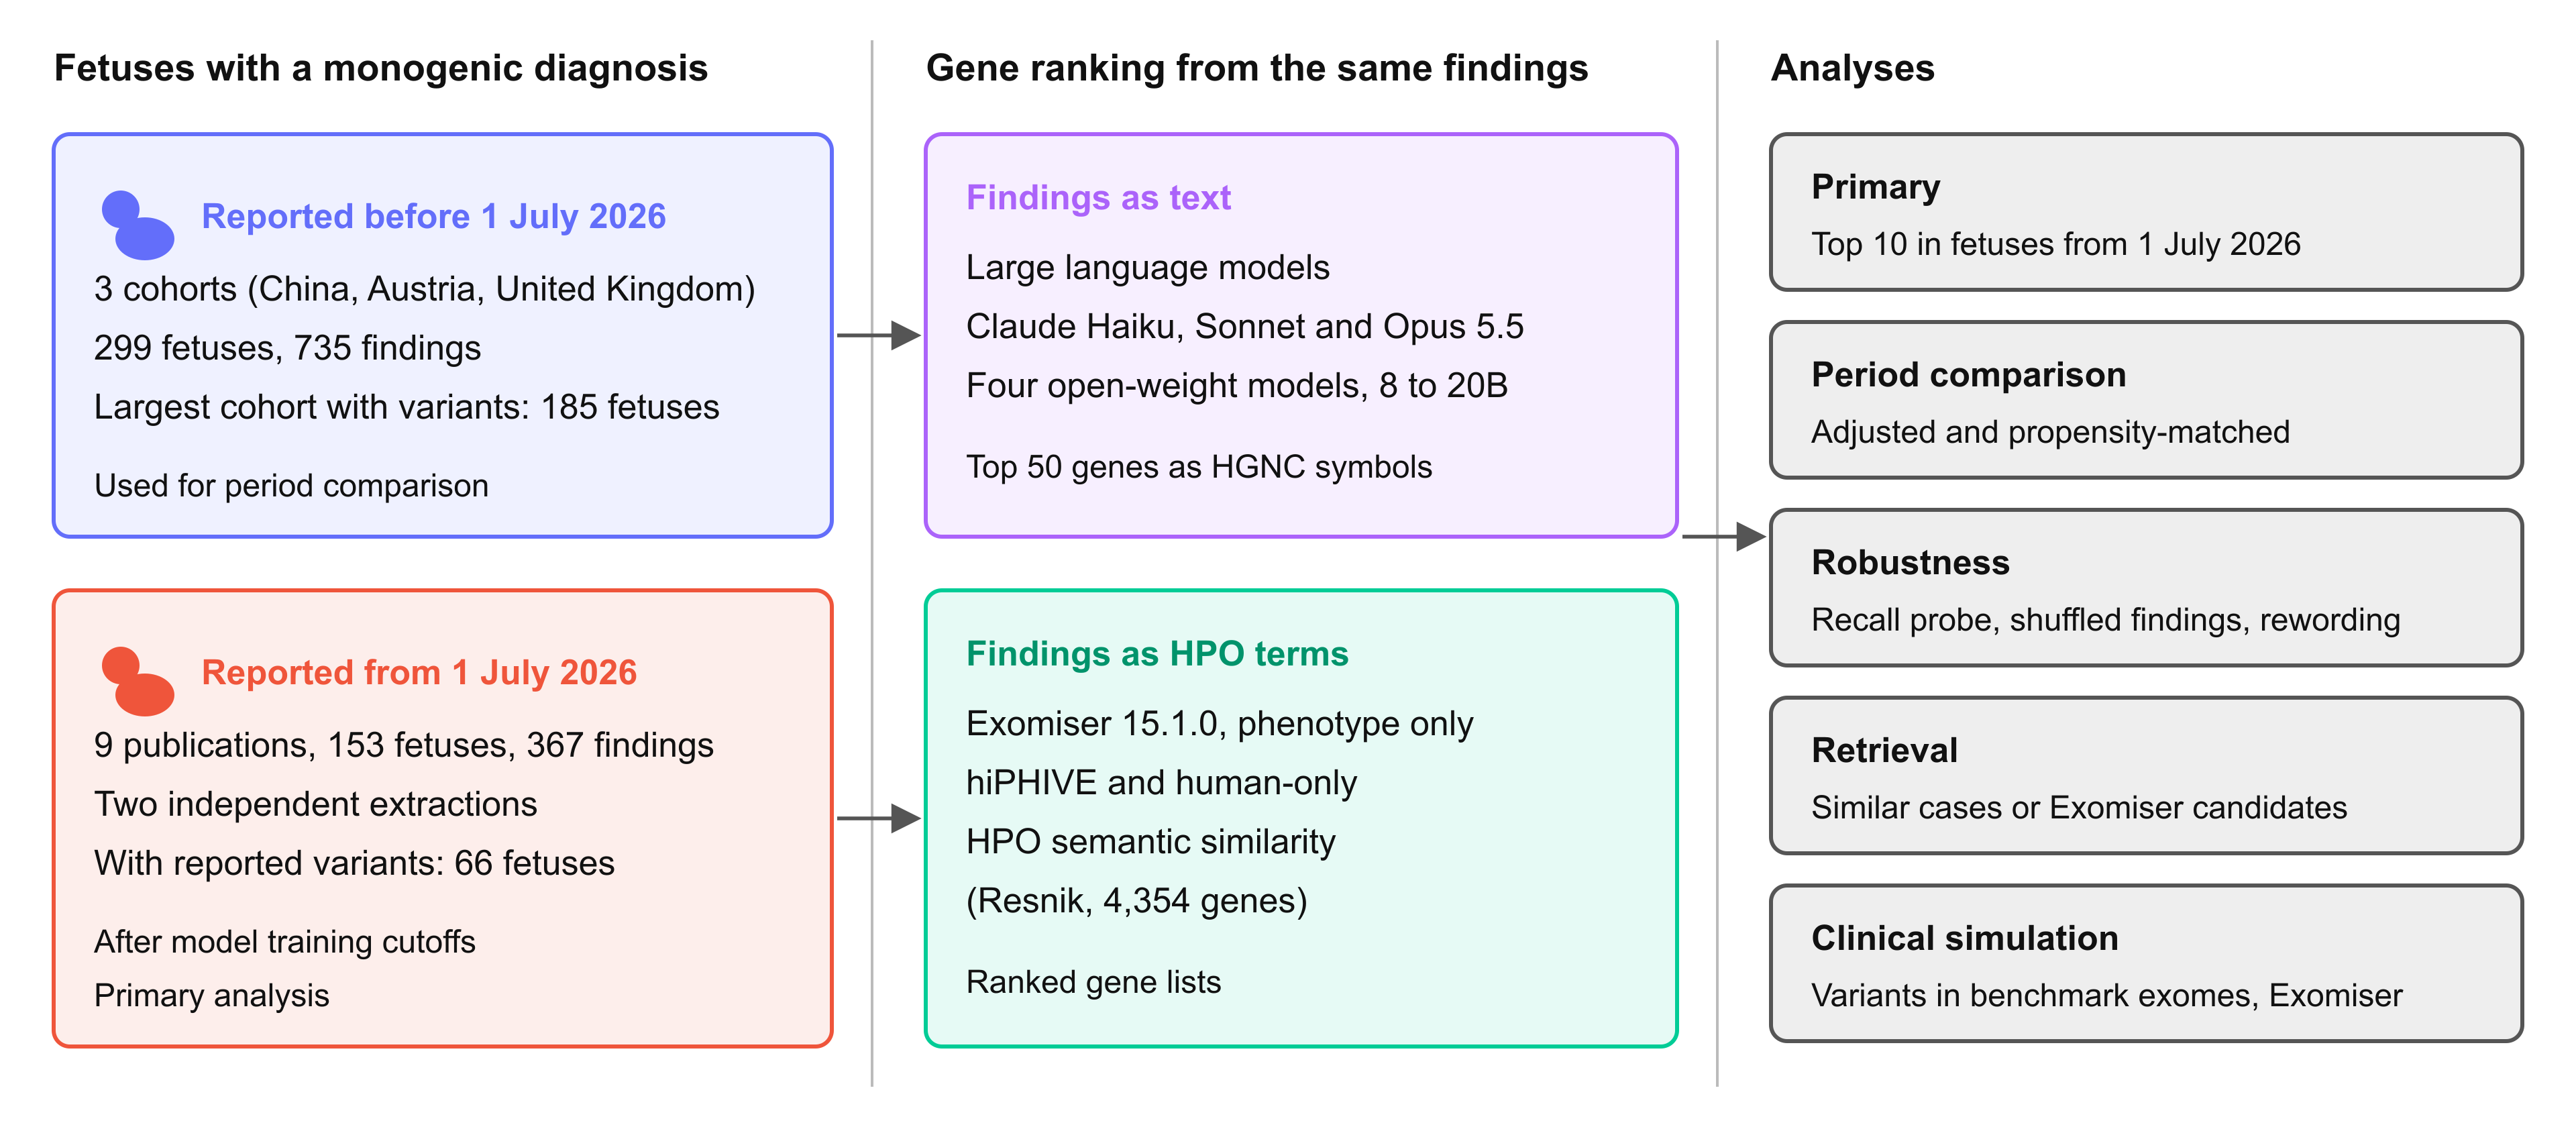

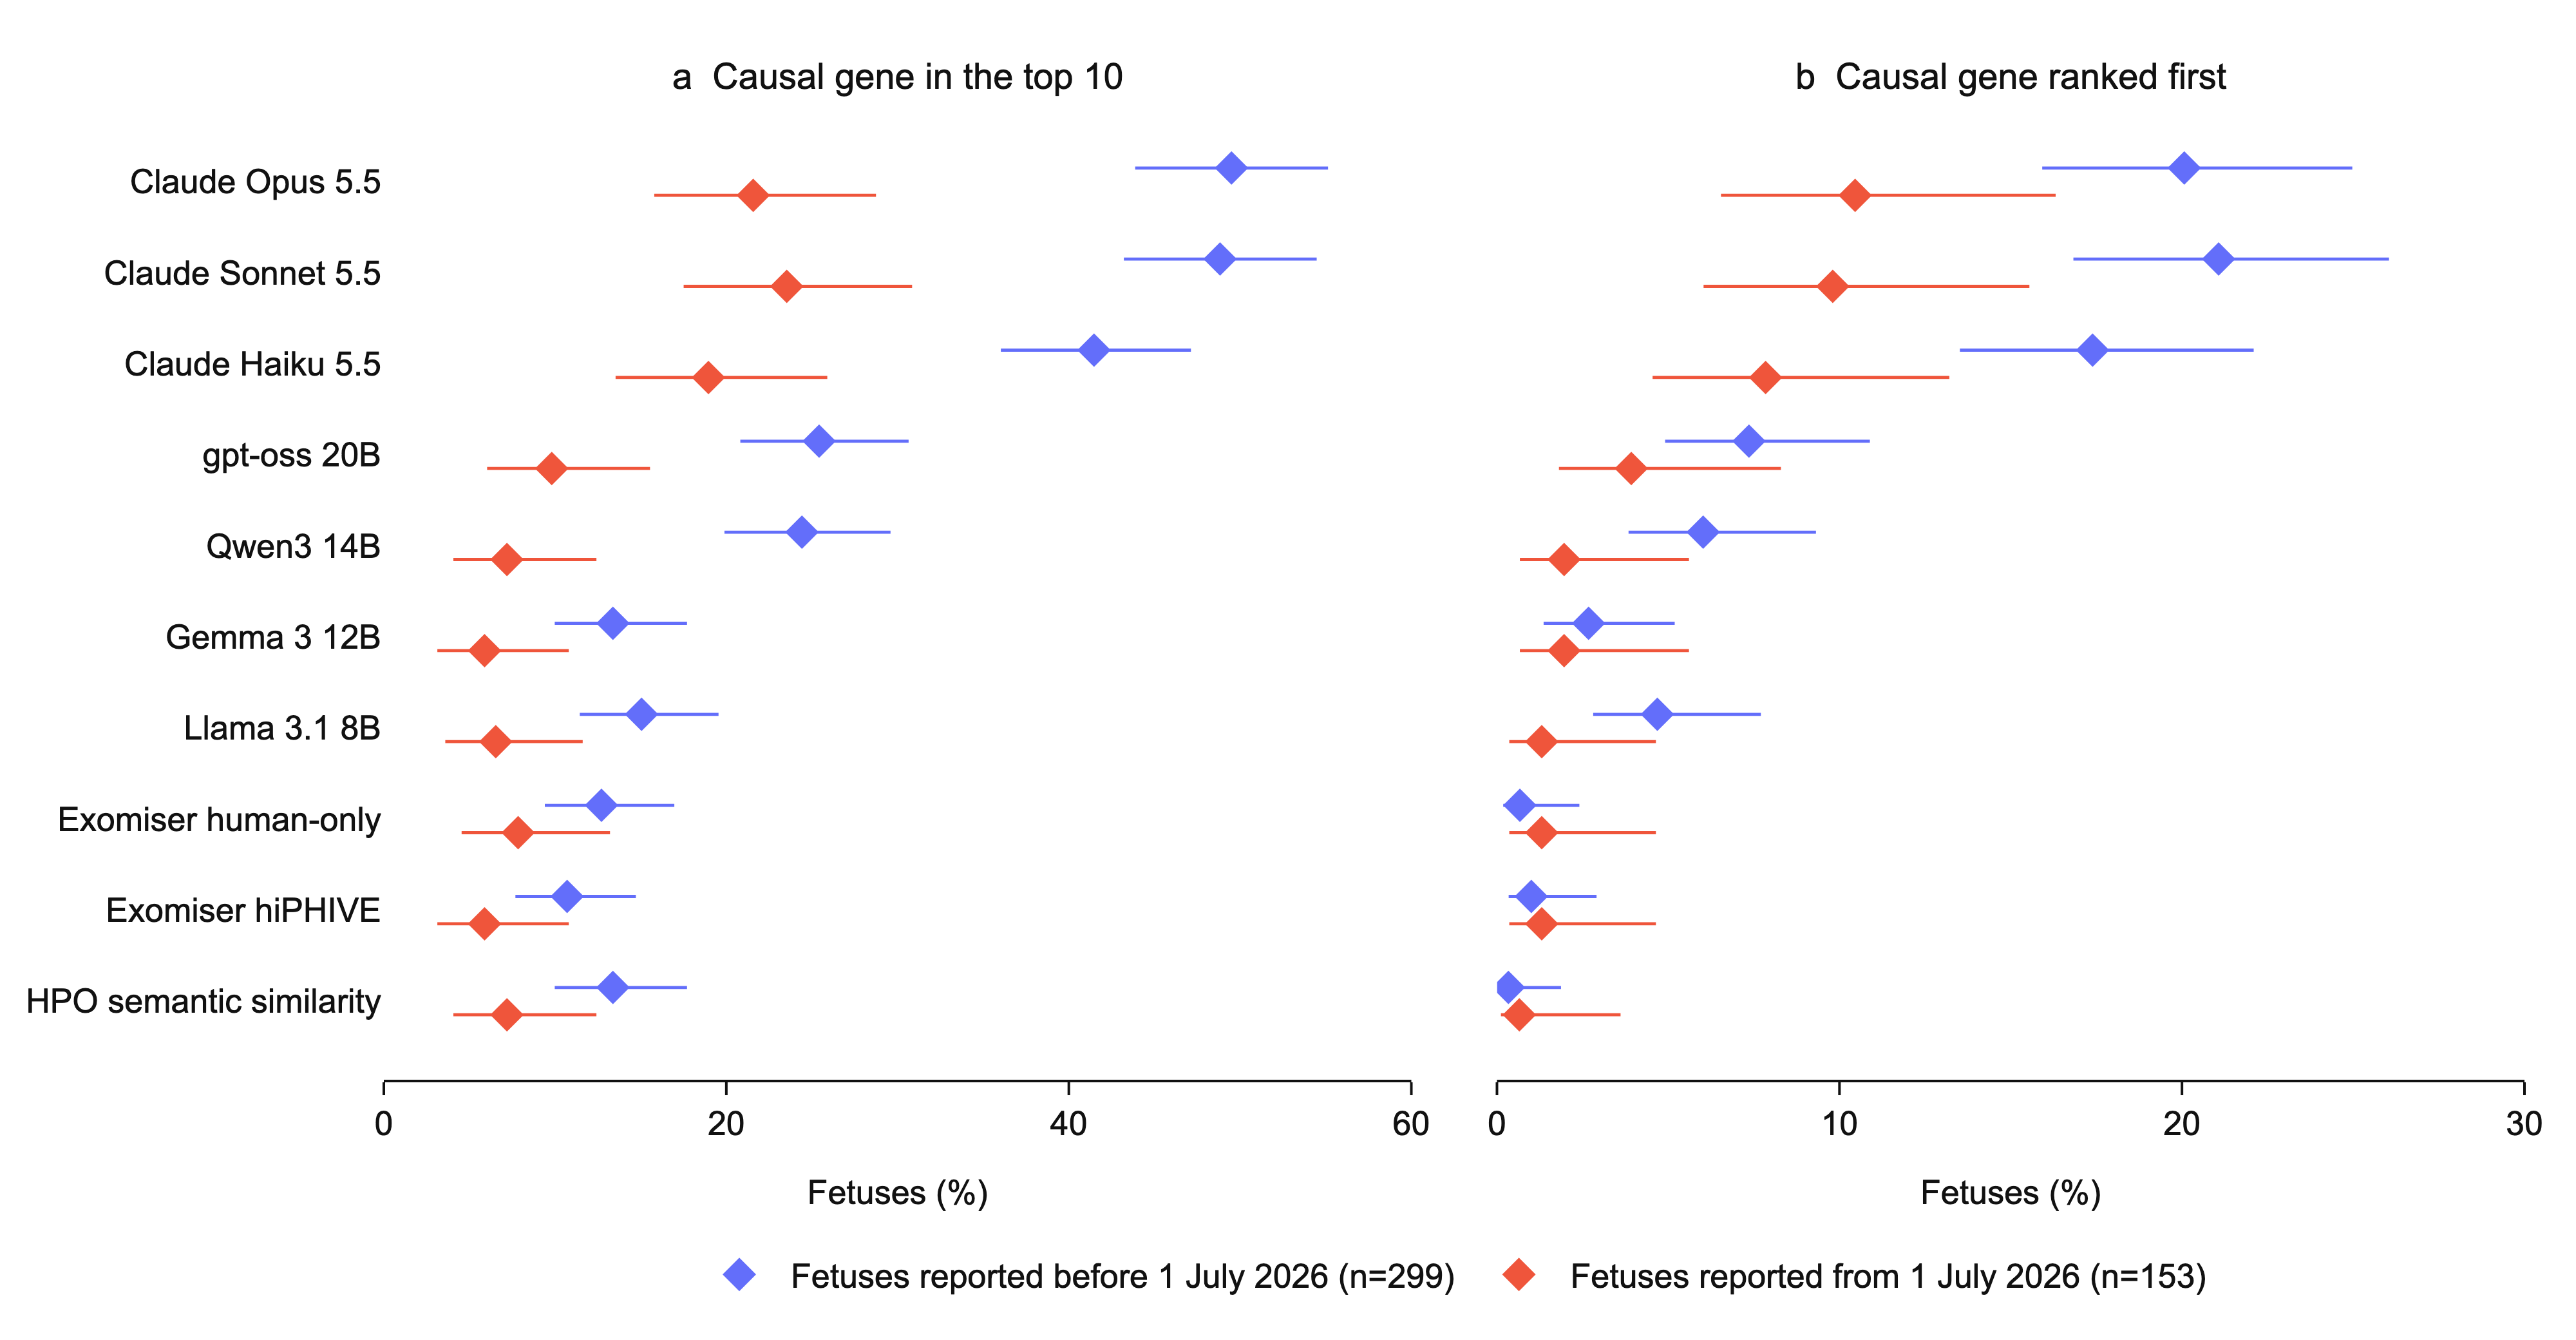

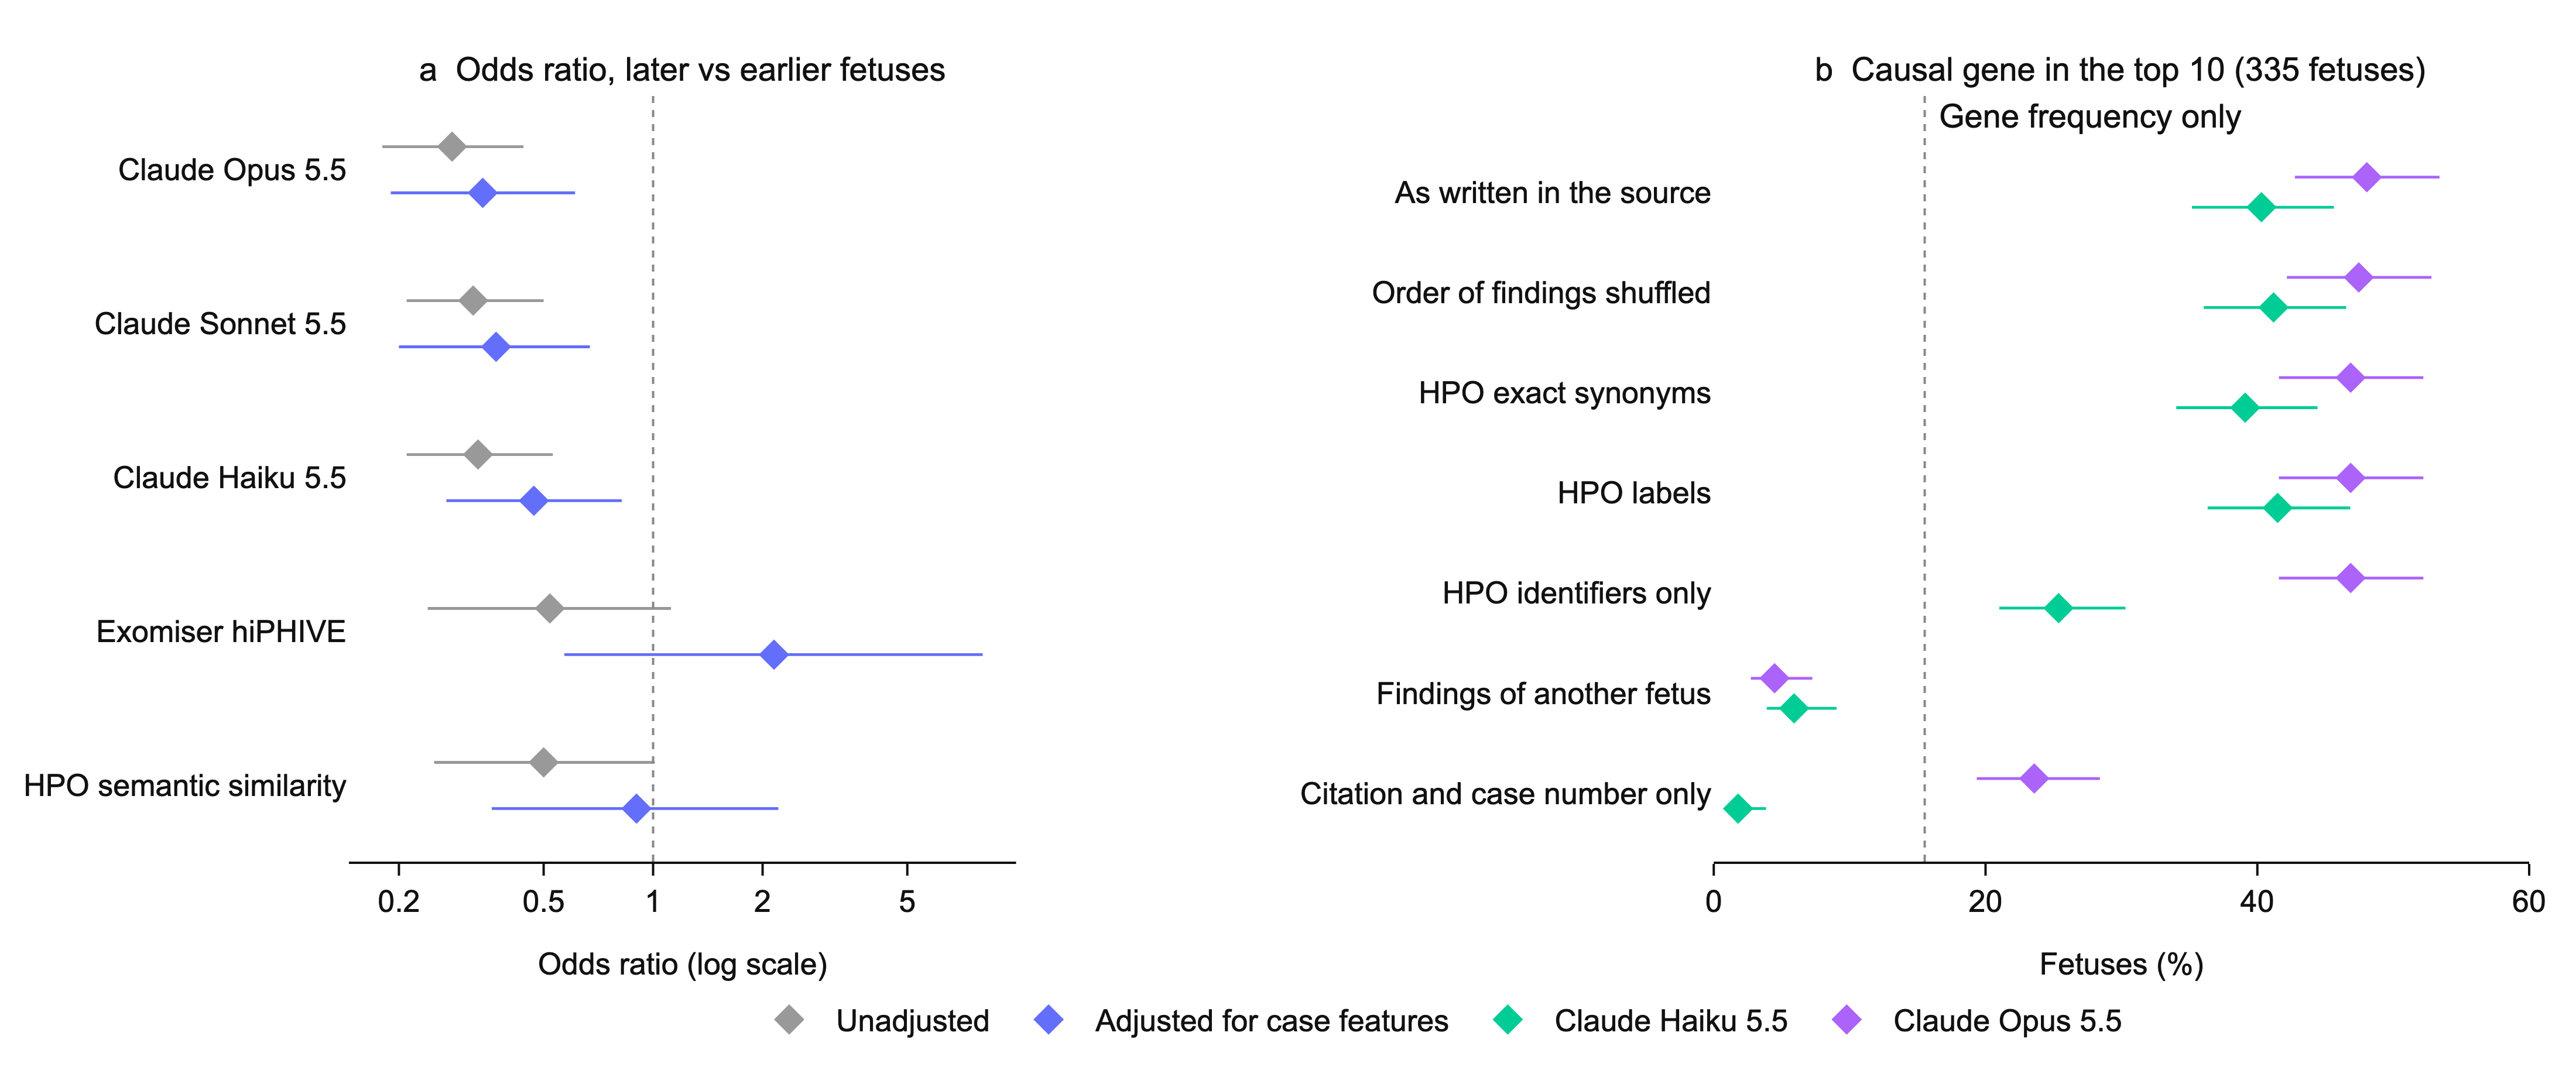

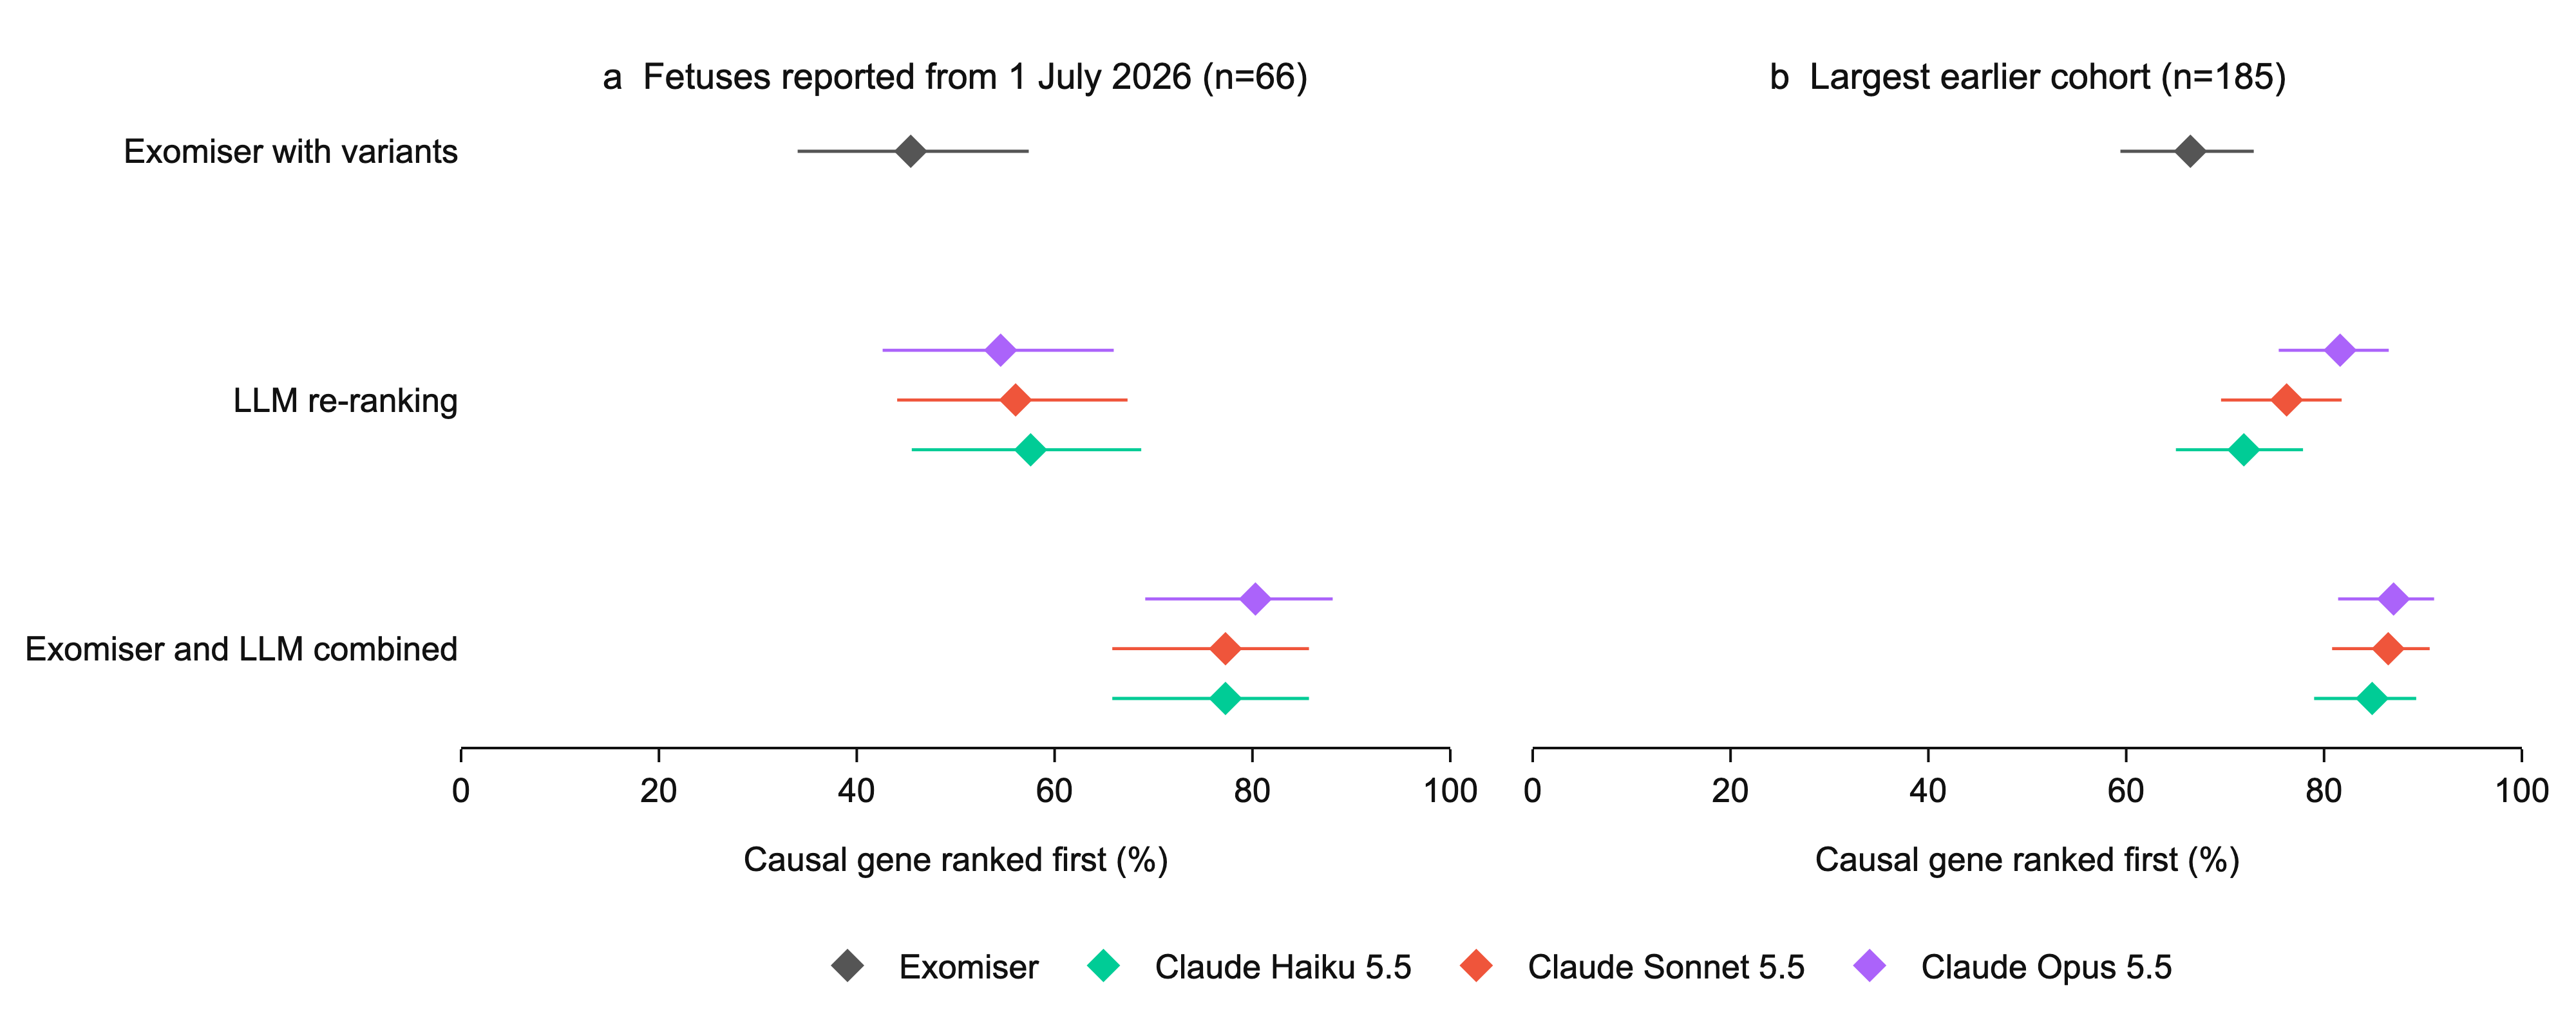

In [11]:
run(PY, 'scripts/fig_data.py')
run(PY, 'scripts/figures.py'); run(PY, 'scripts/figure1.py')
for i in range(1, 5):
    display(Image(f'docs/figures/figure{i}.png', width=900))

## 9. Comparison with the committed results

In [12]:
files = [os.path.join(d, f) for d in ['work', 'outputs'] for f in sorted(os.listdir(os.path.join(REF, d)))
         if os.path.isfile(os.path.join(REF, d, f)) and not f.endswith('.jsonl')]
files += [os.path.join('work/variants', f) for f in sorted(os.listdir(os.path.join(REF, 'work/variants')))]
r = subprocess.run([PY, 'scripts/compare_outputs.py', REF, '.', *files], capture_output=True, text=True)
print(r.stdout)
assert r.returncode == 0

53 files compared
REPRODUCED



## Querying the models again (not run here)

The stored answers were produced on 30 October 2026. Re-running needs an Anthropic API key in `~/.anthropic_key`,
Ollama v0.40.13 with the model digests listed in the Supplementary Information, Exomiser 15.1.0 with data release
2512 and the Genome in a Bottle v4.2.1 call sets (set `GIAB_DIR` and `EXOMISER_DATA`). Claude models do not accept a
temperature setting, so new answers will differ from the stored ones to the extent shown by the three replicates.

* Claude, all prompts: `scripts/claude_batch.py submit <cases.json> <tag> <model> <rep>`, then `collect <tag>`
* Open-weight models: `scripts/run_open.sh`, `scripts/run_open_post.sh`
* Exomiser phenotype-only: `scripts/run_exomiser.py`
* Retrieval: `scripts/run_rag.sh`
* Clinical simulation: `scripts/run_v1.sh` (largest pre-cutoff cohort), `scripts/run_v1p.sh` (post-cutoff)